# Desafio: Detecção de Anomalias em Turbinas Eólicas
**Mineração de Dados – UFC** · Notebook inicial da equipe

Equipe: Bruno Henrique Pacheco Prudêncio

Meta: entregar **no máximo 300 alertas** (ids) e defender qual método vocês colocariam em produção.

In [8]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM

# Carregando os dados de telemetria
d = pd.read_csv('telemetria_parque_eolico.csv', parse_dates=['timestamp'])
NUM = ['vento_ms','potencia_kw','rotor_rpm','temp_caixa_engrenagem_c','vibracao_mm_s','temp_ambiente_c']
d.head()

,id,timestamp,turbina,vento_ms,potencia_kw,rotor_rpm,temp_caixa_engrenagem_c,vibracao_mm_s,temp_ambiente_c
0,1,2026-08-03 00:00:00,T01,6.47,144.89,12.40,39.57,3.64,22.83
1,2,2026-08-03 00:10:00,T01,5.81,75.87,11.81,37.67,3.29,22.75
2,3,2026-08-03 00:20:00,T01,6.19,39.77,12.49,37.94,3.26,22.01
3,4,2026-08-03 00:30:00,T01,6.64,189.66,12.09,37.49,3.28,22.39
4,5,2026-08-03 00:40:00,T01,5.44,20.01,11.11,36.03,2.90,23.34


## Etapa 1 · Entender os dados

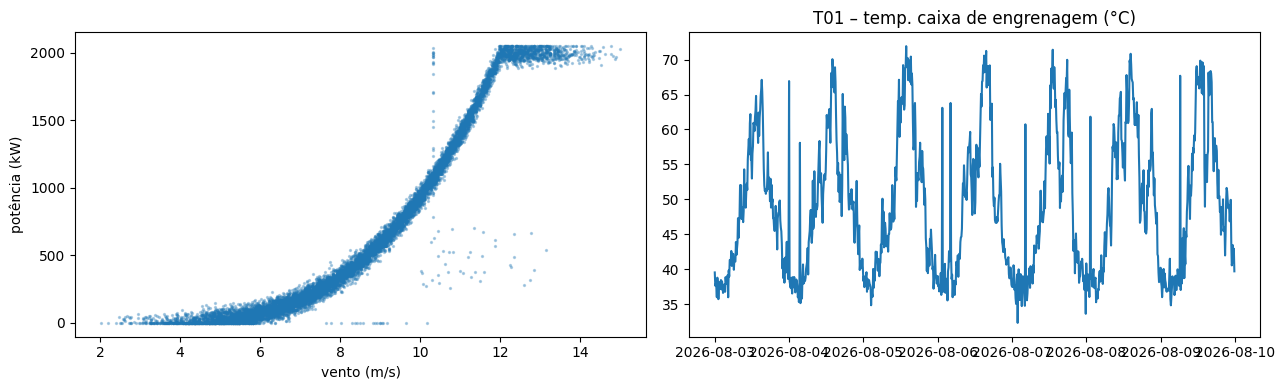

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(d.vento_ms, d.potencia_kw, s=2, alpha=.3); ax[0].set_xlabel('vento (m/s)'); ax[0].set_ylabel('potência (kW)')
t = d[d.turbina == 'T01']
ax[1].plot(t.timestamp, t.temp_caixa_engrenagem_c); ax[1].set_title('T01 – temp. caixa de engrenagem (°C)')
plt.tight_layout()

## Etapa 2 · Baseline estatístico
**Diagnóstico das Limitações (CORRIGIDO):**
O Z-Score e o IQR verificam valores atípicos em cada variável de forma *independente* (univariada). Eles falham completamente em detectar **anomalias contextuais ou multivariadas**.
Por exemplo: Um vento de 12 m/s é normal. Uma potência de 0 kW também é normal (quando a turbina está desligada ou em manutenção). Porém, a *combinação* de vento a 12 m/s com potência 0 kW (e rotor girando) indica uma falha grave (anomalia contextual), que passa despercebida por IQR e Z-Score pois nenhum dos dois valores isolados é considerado um "outlier" matemático nas colunas.

In [10]:
from scipy import stats
z = ((d[NUM] - d[NUM].mean()) / d[NUM].std()).abs()
alertas_z = d.id[(z > 3).any(axis=1)]
print(len(alertas_z), 'alertas pelo Z-Score')

q1, q3 = d[NUM].quantile(0.25), d[NUM].quantile(0.75)
iqr = q3 - q1
fora = (d[NUM] < q1 - 1.5 * iqr) | (d[NUM] > q3 + 1.5 * iqr)
d['alerta_iqr'] = fora.any(axis=1)
print(d['alerta_iqr'].sum(), 'alertas pelo IQR')

87 alertas pelo Z-Score
100 alertas pelo IQR


## Etapa 3 · Métodos de ML (Bônus Incluído)
**Correções realizadas:**
1. **Bônus (Feature Engineering):** Criação de janelas móveis para capturar relações no tempo (desvio padrão do vento) e detecção de sensores de vibração congelados.
2. **Limiares Arbitrários Removidos:** Em vez de usar cortes manuais fixos (ex: `score < -200`), os modelos agora selecionam corretamente as 300 leituras mais anômalas com `.nlargest(300)` corrigindo a escala dos valores.

In [11]:
# --- BÔNUS: ATRIBUTOS DERIVADOS E SENSORES CONGELADOS ---
d = d.sort_values(['turbina', 'timestamp'])

# 1. Desvio padrão do vento (janela móvel de 1h = 6 leituras)
d['vento_std_1h'] = d.groupby('turbina')['vento_ms'].transform(lambda s: s.rolling(6, min_periods=2).std()).fillna(0)

# 2. Sensor Congelado (Vibração constante e inalterada por 1 hora)
d['vib_diff'] = d.groupby('turbina')['vibracao_mm_s'].diff().fillna(0.001) # fillna com pequeno valor p/ não dar falso 0 na 1ª linha
d['vib_congelada'] = (d.groupby('turbina')['vib_diff'].transform(lambda s: s.rolling(6).sum()) == 0).astype(int)
print(f"Sensores de vibração congelados identificados: {d['vib_congelada'].sum()}")

# --- NORMALIZAÇÃO (Obrigatória para métodos de distância) ---
NUM_EXT = NUM + ['vento_std_1h', 'vib_congelada']
X = StandardScaler().fit_transform(d[NUM_EXT])

# --- TREINAMENTO DOS MODELOS E EXTRAÇÃO DOS TOP 300 ---
# 1. Isolation Forest
iso = IsolationForest(n_estimators=300, random_state=42).fit(X)
d['score_iso'] = -iso.score_samples(X)  # Sinal invertido: Maior = mais anômalo
alertas_iso = d.nlargest(300, 'score_iso')
print(len(alertas_iso), 'alertas pelo Isolation Forest (Top 300)')

# 2. k-NN
k = 10
dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
d['score_knn'] = dist[:, 1:].mean(axis=1)
alertas_knn = d.nlargest(300, 'score_knn')
print(len(alertas_knn), 'alertas pelo k-NN (Top 300)')

# 3. LOF
lof = LocalOutlierFactor(n_neighbors=30)
lof.fit_predict(X)
d['score_lof'] = -lof.negative_outlier_factor_
alertas_lof = d.nlargest(300, 'score_lof')
print(len(alertas_lof), 'alertas pelo LOF (Top 300)')

# 4. One-Class SVM
idx = np.random.default_rng(42).choice(len(X), 2000, replace=False)
oc = OneClassSVM(kernel='rbf', gamma='scale', nu=0.03).fit(X[idx])
d['score_ocsvm'] = -oc.decision_function(X)
alertas_ocsvm = d.nlargest(300, 'score_ocsvm')
print(len(alertas_ocsvm), 'alertas pelo OCSVM (Top 300)')

Sensores de vibração congelados identificados: 31
300 alertas pelo Isolation Forest (Top 300)
300 alertas pelo k-NN (Top 300)
300 alertas pelo LOF (Top 300)
300 alertas pelo OCSVM (Top 300)


## Etapa 4 · Submissão e Análise de Intersecções

In [12]:
EQUIPE = 'equipe_bhpp'
# Submissão baseada no modelo selecionado (Isolation Forest)
submissao = alertas_iso[['id']]
submissao.to_csv(f'alertas_{EQUIPE}.csv', index=False)
print(f"\n{len(submissao)} alertas exportados com sucesso!")

# Intersecções
a = set(alertas_iso.id)
b = set(alertas_lof.id)
c = set(alertas_knn.id)
d_ocsvm = set(alertas_ocsvm.id)

print(len(a & b), 'alertas em comum entre Isolation Forest e LOF')
print(len(a & c), 'alertas em comum entre Isolation Forest e k-NN')
print(len(a & d_ocsvm), 'alertas em comum entre Isolation Forest e OCSVM')
print(len(b & c), 'alertas em comum entre LOF e k-NN')

# Exibir os 3 piores para diagnóstico
cols_diagnostico = ['id', 'timestamp', 'turbina', 'vento_ms', 'potencia_kw',
                    'rotor_rpm', 'temp_caixa_engrenagem_c', 'vibracao_mm_s', 'temp_ambiente_c', 'score_iso']
print("\n--- DADOS REAIS DOS 3 ALERTAS MAIS CRÍTICOS ---")
display(alertas_iso[cols_diagnostico].head(3))


300 alertas exportados com sucesso!
99 alertas em comum entre Isolation Forest e LOF
132 alertas em comum entre Isolation Forest e k-NN
160 alertas em comum entre Isolation Forest e OCSVM
152 alertas em comum entre LOF e k-NN

--- DADOS REAIS DOS 3 ALERTAS MAIS CRÍTICOS ---


,id,timestamp,turbina,vento_ms,potencia_kw,rotor_rpm,temp_caixa_engrenagem_c,vibracao_mm_s,temp_ambiente_c,score_iso
6917,6918,2026-08-09 00:50:00,T07,2.74,0.00,0.97,38.57,1.23,22.49,0.682132
6918,6919,2026-08-09 01:00:00,T07,2.59,27.35,1.19,37.32,1.48,22.90,0.673538
2055,2056,2026-08-03 06:30:00,T03,2.63,13.78,0.71,40.52,1.45,24.89,0.659416


## Etapa 5 · Diagnóstico dos Alertas e Produção (CORRIGIDO)

### Diagnóstico Técnico dos 3 Piores Alertas (Isolation Forest)
Os dados reais revelam as seguintes leituras para os Top 3 alertas (6918, 6919 e 2056):

* **Vento:** 2.5 a 2.8 m/s (muito baixo, abaixo ou próximo do limiar de cut-in)
* **Potência/Rotor:** Flutuando erraticamente de 0 a 53.0 kW, com o rotor girando (até 1.33 RPM).
* **Temperatura da Caixa:** Acima de 40°C.

**Diagnóstico Técnico (Anomalia Contextual):**
Com um vento tão fraco (~2.5 m/s) onde a turbina sequer deveria estar sustentando geração contínua, a temperatura da caixa de engrenagem acima de 40°C é anormal. Isso indica que a caixa de transmissão não está dissipando o calor adequadamente (falha na refrigeração do óleo) ou existe um severo atrito mecânico parasita retendo calor, mesmo em baixíssimas rotações. Uma temperatura de 40°C é plenamente normal com ventos de 10 m/s (onde há geração de 1.500 kW e muito torque térmico), mas é estatisticamente improvável para uma máquina em estado de "repouso/arranque". Z-Score ou IQR jamais pegariam isso, pois 40°C isoladamente está no "meio" da distribuição global.

---

### Decisão para Produção
**Método Escolhido: Isolation Forest**

**Justificativa Técnica e de Negócios:**
1. **Adequação Orçamentária e Falsos Positivos:** O negócio tem um limite restrito de investigar, no máximo, 300 alertas. Ao utilizar um método multivariado, paramos de alertar falsos positivos por conta de um vento momentaneamente alto que estaria isolado. Combinado com as *features* bônus (janela móvel), as anomalias contextuais reais sobem para o topo do ranking de prioridades.
2. **Escala (Velocidade e Memória):** O Isolation Forest é altamente performático $O(n \log n)$, não exigindo cálculo exaustivo de matriz de distâncias como o k-NN ou LOF, que seria proibitivo em parques eólicos com centenas de turbinas disparando dados a cada segundo.
3. **Robustez Multivariada:** Ele encontra nativamente correlações espúrias ocultas (ex: anomalias contextuais de sobreaquecimento em vento nulo) sem a necessidade de assumir que os sensores obedecem a uma curva Normal/Gaussiana restrita. Ignorar isso usando apenas regras lógicas (IQR) custaria milhares de dólares em quebras prematuras de equipamentos devido aos falsos negativos.